# 04 — Hybrid Neuro-Symbolic Architecture, Ablation Study & Explainability
### Hybrid Neuro-Symbolic On-Device SMS Fraud Detection — Pipeline Notebook 4 of 5

This notebook assembles the frozen outputs of Notebooks 01–03 into the complete
Hybrid Neuro-Symbolic inference system (Rule Intelligence + DistilBERT + URL
Intelligence + Sender Context, combined through calibrated Score Fusion and a
single Decision Controller), evaluates it against every prior baseline, runs
the full ablation study, and produces the explainability artifacts for the
dissertation.

**This notebook trains nothing.** Notebooks 01–03 are frozen and are only
read from. This notebook consumes their artifacts and is a systems-assembly
and experimental-evaluation notebook, per the frozen Notebook 04 blueprint.


## 1. Setup and Environment Verification

Install pinned dependencies (matching Notebooks 02/03 exactly, so that pickled
scikit-learn artifacts and the DistilBERT checkpoint remain loadable), fix all
random seeds, mount Drive, build the directory tree, verify checksums, and
load every upstream provenance summary before touching any data.


In [1]:
# ── GPU check ────────────────────────────────────────────────────────────
import subprocess
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv"],
                      capture_output=True, text=True).stdout or "No GPU detected — CPU-only session.")


name, memory.total [MiB]
Tesla T4, 15360 MiB



In [2]:
# ── Dependencies ─────────────────────────────────────────────────────────
# VERSION-PINNED to match Notebooks 02 and 03 exactly. This notebook loads
# pickled scikit-learn baselines (NB02) and a saved DistilBERT checkpoint
# (NB03); version drift in either library risks silent unpickling/inference
# incompatibility.
!pip install -q "transformers==4.46.3" "accelerate==1.2.1" "torch==2.11.0" \
    "scikit-learn==1.4.2" "lime==0.2.0.1" "shap==0.46.0" 2>/dev/null
print("Dependencies installed (pinned to Notebook 02/03 versions).")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 12.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 111.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 336.4/336.4 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 87.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 543.9/543.9 kB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 46.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 83.5 MB/s eta 0:00:00
Dependencies installed (pinned to Notebook 02/03 versions).


In [3]:
# ── Imports ──────────────────────────────────────────────────────────────
import os, re, json, random, hashlib, warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import torch
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score, confusion_matrix,
)
from statsmodels.stats.contingency_tables import mcnemar

warnings.filterwarnings("ignore")
print("Imports ready.")


Imports ready.


In [4]:
# ── Reproducibility ──────────────────────────────────────────────────────
# Identical seed to Notebooks 01-03. No component in this notebook is trained,
# so SEED here governs sampling (curated explainability sample, bootstrap CIs,
# ablation weight-search tie-breaking) rather than model initialisation.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f"Seed fixed at {SEED}.")


Seed fixed at 42.


In [5]:
# ── Google Drive mount ────────────────────────────────────────────────────
from google.colab import drive
drive.mount("/content/drive", force_remount=False)


Mounted at /content/drive


In [6]:
# ── Directory structure ───────────────────────────────────────────────────
PROJECT_ROOT = Path("/content/drive/MyDrive/sms_fraud_ml")

DIRS = {
    # Read-only inputs (Notebooks 01 and 02) — paths match those notebooks exactly
    "processed":     PROJECT_ROOT / "data" / "processed",
    "nb02_models":   PROJECT_ROOT / "models" / "baselines",
    "nb02_reports":  PROJECT_ROOT / "reports" / "02_baseline_models",
    "nb02_error":    PROJECT_ROOT / "reports" / "02_baseline_models" / "error_analysis",
    # Read-only inputs (Notebook 03)
    "nb03_model":     PROJECT_ROOT / "models" / "distilbert_fraud_fp32",
    "nb03_tokenizer": PROJECT_ROOT / "models" / "distilbert_fraud_fp32" / "tokenizer",
    "nb03_reports":   PROJECT_ROOT / "reports" / "03_distilbert",
    "nb03_error":     PROJECT_ROOT / "reports" / "03_distilbert" / "error_analysis",
    # This notebook's own outputs
    "reports":       PROJECT_ROOT / "reports" / "04_hybrid",
    "error":         PROJECT_ROOT / "reports" / "04_hybrid" / "error_analysis",
    "figures":       PROJECT_ROOT / "reports" / "04_hybrid" / "figures",
}

# Never create inside Notebooks 01/02/03 output dirs — read-only contract
_READ_ONLY = ("processed", "nb02_models", "nb02_reports", "nb02_error",
              "nb03_model", "nb03_tokenizer", "nb03_reports", "nb03_error")
for name, path in DIRS.items():
    if name not in _READ_ONLY:
        path.mkdir(parents=True, exist_ok=True)
(DIRS["figures"] / "confusion_matrices").mkdir(exist_ok=True)
(DIRS["figures"] / "roc_curves").mkdir(exist_ok=True)
(DIRS["figures"] / "pr_curves").mkdir(exist_ok=True)
(DIRS["figures"] / "lime_attention_comparison").mkdir(exist_ok=True)

print("Directory structure ready:")
for name, path in DIRS.items():
    marker = " [read-only]" if name in _READ_ONLY else ""
    print(f"  {name:<14} -> {path}{marker}")


Directory structure ready:
  processed      -> /content/drive/MyDrive/sms_fraud_ml/data/processed [read-only]
  nb02_models    -> /content/drive/MyDrive/sms_fraud_ml/models/baselines [read-only]
  nb02_reports   -> /content/drive/MyDrive/sms_fraud_ml/reports/02_baseline_models [read-only]
  nb02_error     -> /content/drive/MyDrive/sms_fraud_ml/reports/02_baseline_models/error_analysis [read-only]
  nb03_model     -> /content/drive/MyDrive/sms_fraud_ml/models/distilbert_fraud_fp32 [read-only]
  nb03_tokenizer -> /content/drive/MyDrive/sms_fraud_ml/models/distilbert_fraud_fp32/tokenizer [read-only]
  nb03_reports   -> /content/drive/MyDrive/sms_fraud_ml/reports/03_distilbert [read-only]
  nb03_error     -> /content/drive/MyDrive/sms_fraud_ml/reports/03_distilbert/error_analysis [read-only]
  reports        -> /content/drive/MyDrive/sms_fraud_ml/reports/04_hybrid
  error          -> /content/drive/MyDrive/sms_fraud_ml/reports/04_hybrid/error_analysis
  figures        -> /content/drive/MyD

In [7]:
# ── Plotting defaults ─────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 300


In [8]:
# ── Checksum verification ─────────────────────────────────────────────────
# Same NB01 checksum contract used by NB02 and NB03. This notebook does not
# regenerate data — it only re-verifies the frozen files it reads are the
# ones NB01 produced.
with open(DIRS["processed"] / "checksums.txt") as f:
    expected_checksums = dict(
        line.strip().split("  ", 1)[::-1] for line in f if line.strip()
    )

verified = 0
for fname, expected_hash in expected_checksums.items():
    fpath = DIRS["processed"] / fname
    actual_hash = hashlib.sha256(fpath.read_bytes()).hexdigest()
    assert actual_hash == expected_hash, f"CHECKSUM MISMATCH: {fname}"
    verified += 1
print(f"Checksum verification PASSED for {verified} file(s).")


Checksum verification PASSED for 3 file(s).


In [9]:
# ── Load upstream provenance summaries ───────────────────────────────────
with open(DIRS["processed"] / "dataset_summary.json") as f:
    dataset_summary = json.load(f)
with open(DIRS["processed"] / "label_mapping.json") as f:
    label_mapping = json.load(f)

with open(DIRS["nb02_reports"] / "02_baseline_summary.json") as f:
    nb02_summary = json.load(f)
with open(DIRS["nb03_reports"] / "03_distilbert_summary.json") as f:
    nb03_summary = json.load(f)
with open(DIRS["nb03_reports"] / "distilbert_training_args.json") as f:
    nb03_training_args = json.load(f)

# Frozen scalars this notebook depends on but does not recompute
BASELINE_FLOOR       = nb02_summary["best_baseline"]["test_f1"]
BEST_BASELINE_MODEL  = nb02_summary["best_baseline"]["model"]
OPERATING_THRESHOLD  = nb03_summary["threshold"]["operating_threshold"]

# label columns in train/validation/test.csv hold the literal strings
# "ham"/"fraud" (never 0/1) — matching NB01/02/03's own convention exactly.
# HAM_LABEL/FRAUD_LABEL are those strings; numeric 0/1 targets are derived
# from them wherever sklearn needs a numeric y (e.g. y_test, y_val below).
binary_labels = label_mapping["binary_labels"]
assert binary_labels == ["ham", "fraud"], (
    f"Unexpected label order in label_mapping.json: {binary_labels}. "
    "Expected ['ham', 'fraud']."
)
HAM_LABEL, FRAUD_LABEL = "ham", "fraud"

print("Provenance loaded:")
print(f"  NB01 generated : {dataset_summary['generated_at_utc']}")
print(f"  NB02 best model: {BEST_BASELINE_MODEL} (F1={BASELINE_FLOOR:.4f})")
print(f"  NB03 OPERATING_THRESHOLD (ML engine only) : {OPERATING_THRESHOLD:.2f}")
print(f"  Positive label : '{FRAUD_LABEL}' (encoded as 1)  Negative label: '{HAM_LABEL}' (encoded as 0)")


Provenance loaded:
  NB01 generated : 2026-07-01T11:16:16.785545+00:00
  NB02 best model: linear_svm (F1=0.9734)
  NB03 OPERATING_THRESHOLD (ML engine only) : 0.25
  Positive label : 'fraud' (encoded as 1)  Negative label: 'ham' (encoded as 0)


## 2. Data Loading and Validation

Load the three frozen splits (validating row counts against `dataset_summary.json`),
quarantine the test split under the same `_HOLDOUT` naming convention used in
Notebooks 02 and 03, and load every NB02/NB03 prediction and error-analysis
artifact this notebook depends on. `baseline_results.csv`'s schema is
validated here, before any append later in the notebook.


In [10]:
# ── Load splits ───────────────────────────────────────────────────────────
train_df       = pd.read_csv(DIRS["processed"] / "train.csv")
val_df         = pd.read_csv(DIRS["processed"] / "validation.csv")
test_df_HOLDOUT = pd.read_csv(DIRS["processed"] / "test.csv")   # quarantined — see Section 6

# label columns hold "ham"/"fraud" strings — validated the same way NB02/03 do.
expected_splits = dataset_summary["splits"]
for name, df, key in [
    ("train", train_df, "train"),
    ("validation", val_df, "validation"),
    ("test", test_df_HOLDOUT, "test"),
]:
    exp_rows = expected_splits[key]["rows"]
    assert len(df) == exp_rows, f"{name} row count mismatch: {len(df)} != {exp_rows}"
    assert set(df["label"].unique()) <= {"ham", "fraud"}, (
        f"Unexpected label values in {name}: {df['label'].unique()}"
    )

print("Row counts and label values validated against dataset_summary.json:")
print(f"  train      : {len(train_df):,}")
print(f"  validation : {len(val_df):,}")
print(f"  test [HOLDOUT] : {len(test_df_HOLDOUT):,}  (not touched until Section 6)")


Row counts and label values validated against dataset_summary.json:
  train      : 52,101
  validation : 11,165
  test [HOLDOUT] : 11,165  (not touched until Section 6)


In [11]:
# ── Load Notebook 02 artifacts (classical baselines, ablation conditions) ──
tfidf_vectorizer = joblib.load(DIRS["nb02_models"] / "tfidf_vectorizer.pkl")
lr_model         = joblib.load(DIRS["nb02_models"] / "baseline_lr_best.pkl")
svm_model        = joblib.load(DIRS["nb02_models"] / "baseline_svm_best.pkl")

with open(DIRS["nb02_models"] / "preprocessing_config.json") as f:
    preproc_spec = json.load(f)

nb02_fp = pd.read_csv(DIRS["nb02_error"] / "baseline_false_positives.csv")
nb02_fn = pd.read_csv(DIRS["nb02_error"] / "baseline_false_negatives.csv")

print("Notebook 02 artifacts loaded (read-only): TF-IDF vectoriser, LR, SVM, "
      f"preprocessing spec, {len(nb02_fp):,} FPs, {len(nb02_fn):,} FNs.")


Notebook 02 artifacts loaded (read-only): TF-IDF vectoriser, LR, SVM, preprocessing spec, 123 FPs, 114 FNs.


In [12]:
# ── Load Notebook 03 artifacts (frozen DistilBERT engine) ────────────────
distilbert_test_predictions = pd.read_csv(DIRS["nb03_reports"] / "distilbert_test_predictions.csv")
distilbert_val_predictions  = pd.read_csv(DIRS["nb03_reports"] / "distilbert_val_predictions.csv")
cross_model_analysis        = pd.read_csv(DIRS["nb03_error"] / "cross_model_analysis.csv")
nb03_fp = pd.read_csv(DIRS["nb03_error"] / "distilbert_false_positives.csv")
nb03_fn = pd.read_csv(DIRS["nb03_error"] / "distilbert_false_negatives.csv")

# Tokenizer + checkpoint loaded once, for the curated live-inference sample in
# Section 9 only. Test-set scoring uses the pre-computed CSVs above.
distilbert_tokenizer = DistilBertTokenizerFast.from_pretrained(str(DIRS["nb03_tokenizer"]))
distilbert_model = DistilBertForSequenceClassification.from_pretrained(str(DIRS["nb03_model"]))
device = "cuda" if torch.cuda.is_available() else "cpu"
distilbert_model.to(device).eval()

print("Notebook 03 artifacts loaded (read-only, no retraining):")
print(f"  test predictions : {len(distilbert_test_predictions):,} rows")
print(f"  val predictions  : {len(distilbert_val_predictions):,} rows")
print(f"  cross-model analysis (SVM vs DistilBERT) : {len(cross_model_analysis):,} rows")
print(f"  checkpoint loaded to {device} for curated explainability inference only")


Notebook 03 artifacts loaded (read-only, no retraining):
  test predictions : 11,165 rows
  val predictions  : 11,165 rows
  cross-model analysis (SVM vs DistilBERT) : 11,165 rows
  checkpoint loaded to cuda for curated explainability inference only


In [13]:
# ── Schema validation: baseline_results.csv (before any append) ─────────
EXPECTED_BASELINE_COLS = [
    "model","split","accuracy","precision","recall","f1","roc_auc",
    "f1_at_threshold","f1_ci_lower","f1_ci_upper","auc_ci_lower","auc_ci_upper",
]
baseline_results_path = DIRS["nb02_reports"] / "baseline_results.csv"
baseline_results = pd.read_csv(baseline_results_path)
assert list(baseline_results.columns) == EXPECTED_BASELINE_COLS, (
    "baseline_results.csv schema mismatch — halting before any further work."
)
print(f"baseline_results.csv schema PASSED ({len(baseline_results)} existing rows).")
print(baseline_results[baseline_results['split']=='test']
      [['model','f1','roc_auc']].to_string(index=False))


baseline_results.csv schema PASSED (8 existing rows).
                model       f1  roc_auc
  logistic_regression 0.972852 0.996233
           linear_svm 0.973392 0.996143
      distilbert_fp32 0.983728 0.998682
hybrid_neuro_symbolic 0.976660 0.996934


## 3. Component Implementations

Each engine is implemented as an independently testable class with a strict,
documented interface. Per the frozen architecture:

- **Rule Engine** — text-only, deterministic, emits rule outputs only.
- **URL Engine** — URL analysis only.
- **Sender Context Engine** — sender metadata only; the *sole* source of
  `trusted_sender_recommendation` in the system (see the Notebook 04
  blueprint's Revision 1 — no rule produces a sender-trust signal).
- **DistilBERT ML Engine** — a thin wrapper around the frozen NB03 checkpoint;
  scores test/val messages from the pre-computed CSVs, with live inference
  available only for messages outside those CSVs (curated explainability
  sample, Section 9).

Unit tests for each engine run at the end of this section, before any
system-level evaluation.


In [14]:
# ── 3.1 Preprocessing (loaded from Notebook 02's frozen spec) ────────────
# Identical contract to Notebooks 02 and 03: reconstructed from the saved
# JSON rather than re-typed, to guarantee behavioural parity. No lowercasing
# here, matching NB03's preprocess_for_distilbert exactly (the substitution
# patterns are IGNORECASE, so case doesn't affect substitution correctness).
_subs = [
    (re.compile(rule["pattern"], re.IGNORECASE), f"[{rule['name']}]")
    for rule in preproc_spec["substitution_rules"]
]
_ws_re = re.compile(r"\s+")

# Reuse the exact URL pattern from the frozen spec (not a separately
# hand-rolled regex) so the URL Engine's candidate list is extracted with
# the same rule NB02/NB03 already use for substitution.
_url_rule = next(r for r in preproc_spec["substitution_rules"] if r["name"] == "URL")
_url_re = re.compile(_url_rule["pattern"], re.IGNORECASE)

def preprocess_message(raw_text: str):
    '''Returns (message_clean, url_list) for one raw message. message_clean
    uses the same substitution + whitespace rules as NB02/NB03. url_list is
    the raw URL substrings (for the URL Engine's own pattern analysis) —
    note url_present itself is read from the frozen NB01 `has_url` column
    wherever a full row is available (see run_hybrid_pipeline in Section 4),
    not re-derived here, so it stays authoritative and survives URL Engine
    ablation.'''
    text = str(raw_text)
    url_list = _url_re.findall(text)
    for pattern, token in _subs:
        text = pattern.sub(token, text)
    message_clean = _ws_re.sub(" ", text).strip()
    return message_clean, url_list

print("Preprocessing function reconstructed from preprocessing_config.json "
      f"(models/baselines/), URL pattern reused from its 'URL' substitution rule.")


Preprocessing function reconstructed from preprocessing_config.json (models/baselines/), URL pattern reused from its 'URL' substitution rule.


In [15]:
# ── 3.2 Rule Intelligence Engine (text-only, deterministic) ──────────────
# Eight text-only rules per the frozen architecture. ContactTrustBypass is
# NOT part of this engine (Notebook 04 blueprint Revision 1) — sender-trust
# logic belongs exclusively to the Sender Context Engine in Section 3.4.
RULE_PATTERNS = {
    "CredentialHarvest":    re.compile(r"\b(verify|confirm|update)\b.{0,25}\b(account|password|kyc|pan|otp)\b", re.I),
    "KnownPhishingTemplate":re.compile(r"\b(account.{0,10}(suspend|block|lock)|kyc.{0,10}(expire|pending))\b", re.I),
    "GovtImpersonation":    re.compile(r"\b(income.?tax|irs|customs|police|court|fine)\b.{0,20}\b(pay|penalty|due)\b", re.I),
    "RewardScam":           re.compile(r"\b(congratulations|winner|lucky draw|lottery|prize|cashback|reward)\b", re.I),
    "OTPDetect":            re.compile(r"\botp\b.{0,15}\b\d{4,8}\b", re.I),
    "BankTransactionTemplate": re.compile(r"\b(debited|credited|a/c|acct)\b.{0,20}\b(rs\.?|inr|\[AMOUNT\])\b", re.I),
    "DeliveryNotification": re.compile(r"\b(parcel|package|courier|shipment|out for delivery)\b", re.I),
    "UrgencyPhrase":        re.compile(r"\b(act now|immediately|urgent|within 24 hours|expire[sd]? (today|soon))\b", re.I),
}

# Rules that terminate the pipeline outright vs. rules that only contribute a
# score. Consistent with Section 5: FORCE_PASS is a recommendation, resolved
# against url_present at the Decision Controller, never a terminal action here.
FORCE_BLOCK_RULES = {"CredentialHarvest", "KnownPhishingTemplate"}
FORCE_PASS_RULES  = {"OTPDetect", "BankTransactionTemplate", "DeliveryNotification"}

class RuleEngine:
    '''Text-only, deterministic. Accepts message_clean only.
    Returns {action, rule_label, rule_confidence, rule_score}.'''

    def score(self, message_clean: str) -> dict:
        for label, pattern in RULE_PATTERNS.items():
            if pattern.search(message_clean):
                if label in FORCE_BLOCK_RULES:
                    return {"action": "FORCE_BLOCK", "rule_label": label,
                            "rule_confidence": 0.95, "rule_score": 1.0}
                if label in FORCE_PASS_RULES:
                    return {"action": "FORCE_PASS", "rule_label": label,
                            "rule_confidence": 0.85, "rule_score": 0.0}
                # Remaining rules (RewardScam, GovtImpersonation, UrgencyPhrase)
                # contribute a score without a terminal action.
                return {"action": "SCORE", "rule_label": label,
                        "rule_confidence": 0.75, "rule_score": 0.80}
        return {"action": "SCORE", "rule_label": "normal",
                "rule_confidence": 0.60, "rule_score": 0.50}

rule_engine = RuleEngine()
print(f"Rule Intelligence Engine ready ({len(RULE_PATTERNS)} text-only rules).")


Rule Intelligence Engine ready (8 text-only rules).


In [16]:
# ── 3.3 URL Intelligence Engine (URL analysis only) ──────────────────────
# Research-prototype, Bloom-filter-equivalent in-process lookup: a curated
# set of known-malicious domain patterns, TLD risk scoring, shortener
# detection, and path heuristics. Not the production Bloom filter (deferred
# to the Android app / Notebook 05), but functionally equivalent for
# evaluation purposes, per the blueprint's stated scope.
KNOWN_MALICIOUS_PATTERNS = [
    re.compile(r"secure-?(login|verify|update)", re.I),
    re.compile(r"(bank|kyc|paytm|upi)-?(verify|update|confirm)", re.I),
    re.compile(r"\.(tk|ml|ga|cf|gq)(/|$)", re.I),          # high-risk free TLDs
]
URL_SHORTENERS = re.compile(r"(bit\.ly|tinyurl|t\.co|goo\.gl|is\.gd|cutt\.ly)", re.I)
HIGH_RISK_TLDS = re.compile(r"\.(tk|ml|ga|cf|gq|xyz|top)(/|$)", re.I)

class URLEngine:
    '''Accepts the extracted URL list from preprocessing.
    Returns {url_risk, url_confidence, url_label, url_present}.'''

    def score(self, url_list: list, url_present: bool) -> dict:
        if not url_present:
            return {"url_risk": 0.0, "url_confidence": 1.0,
                    "url_label": "no_url", "url_present": False}

        risk = 0.20  # baseline non-zero risk for presence of any URL
        label = "unclassified_url"
        for url in url_list:
            if any(p.search(url) for p in KNOWN_MALICIOUS_PATTERNS):
                risk = max(risk, 0.95); label = "known_malicious_pattern"
            if HIGH_RISK_TLDS.search(url):
                risk = max(risk, 0.75); label = "high_risk_tld" if label == "unclassified_url" else label
            if URL_SHORTENERS.search(url):
                risk = max(risk, 0.60); label = "shortener" if label == "unclassified_url" else label

        confidence = 0.90 if label != "unclassified_url" else 0.65
        return {"url_risk": float(risk), "url_confidence": confidence,
                "url_label": label, "url_present": True}

url_engine = URLEngine()
print("URL Intelligence Engine ready.")


URL Intelligence Engine ready.


In [17]:
# ── 3.4 Sender Context Engine (sender metadata only) ─────────────────────
# Sole owner of trusted_sender_recommendation (Notebook 04 blueprint,
# Revision 1). Stateless, per-message: a real contact-book lookup is an
# Android-app concern; here it is simulated from dataset metadata, which is
# documented explicitly as a research approximation (blueprint Risk 2).
class SenderContextEngine:
    '''Accepts sender metadata for one row.
    Returns {sender_risk, sender_confidence, sender_label,
             sender_in_contacts, trusted_sender_recommendation}.'''

    TRUSTED_CATEGORIES = {"otp", "banking"}

    def score(self, row: pd.Series) -> dict:
        source = str(row.get("source", "unknown"))
        rule_category = str(row.get("rule_category", "normal"))

        if source == "synthetic":
            # Synthetic-source messages are simulated as unknown senders.
            return {"sender_risk": 0.55, "sender_confidence": 0.55,
                    "sender_label": "unknown_sender",
                    "sender_in_contacts": False,
                    "trusted_sender_recommendation": False}

        if rule_category in self.TRUSTED_CATEGORIES:
            # Real-source metadata matching OTP/banking patterns is simulated
            # as a registered business sender.
            return {"sender_risk": 0.10, "sender_confidence": 0.85,
                    "sender_label": "registered_business_sender",
                    "sender_in_contacts": True,
                    "trusted_sender_recommendation": True}

        return {"sender_risk": 0.40, "sender_confidence": 0.65,
                "sender_label": "unregistered_sender",
                "sender_in_contacts": False,
                "trusted_sender_recommendation": False}

sender_engine = SenderContextEngine()
print("Sender Context Engine ready (sole source of trusted_sender_recommendation).")


Sender Context Engine ready (sole source of trusted_sender_recommendation).


In [18]:
# ── 3.5 DistilBERT ML Engine wrapper ──────────────────────────────────────
# Primary path: read continuous probabilities from NB03's frozen CSVs.
# Fallback path: live inference, used only for curated messages in Section 9
# that are not present in those CSVs. ml_score is ALWAYS continuous — never
# binarized before Score Fusion (blueprint Revision 2).
_test_proba_by_id = dict(zip(distilbert_test_predictions["row_id"],
                              distilbert_test_predictions["y_proba_fraud"]))
_val_proba_by_id  = dict(zip(distilbert_val_predictions["row_id"],
                              distilbert_val_predictions["y_proba_fraud"]))

def ml_confidence_from_proba(proba, threshold=OPERATING_THRESHOLD):
    """Distance from OPERATING_THRESHOLD, normalized separately on each side
    so both proba=0 and proba=1 correctly reach confidence=1.0. Fixes the
    asymmetric-scaling bug in the previous flat `*2` formula, while keeping
    confidence anchored on this engine's own decision boundary (0.25), not
    an arbitrary 0.5, matching the original design intent."""
    if proba <= threshold:
        return float(threshold - proba) / threshold
    return float(proba - threshold) / (1.0 - threshold)

class MLEngine:
    def score_from_cache(self, row_id, split: str) -> dict:
        cache = _test_proba_by_id if split == "test" else _val_proba_by_id
        proba = cache[row_id]
        confidence = ml_confidence_from_proba(proba)
        return {"ml_score": float(proba), "ml_confidence": confidence}

    @torch.no_grad()
    def score_live(self, message_clean: str) -> dict:
        inputs = distilbert_tokenizer(message_clean, truncation=True, padding="max_length",
                                       max_length=nb03_training_args["max_length"], return_tensors="pt").to(device)
        logits = distilbert_model(**inputs).logits
        proba = torch.softmax(logits, dim=-1)[0, 1].item()
        confidence = ml_confidence_from_proba(proba)
        return {"ml_score": proba, "ml_confidence": confidence}

ml_engine = MLEngine()
print("ML Engine wrapper ready (cached-CSV primary path, live-inference fallback).")


ML Engine wrapper ready (cached-CSV primary path, live-inference fallback).


In [19]:
# ── 3.6 Unit tests — run before any system-level evaluation ──────────────
def _test_rule_engine():
    r = rule_engine.score("your account has been suspended, verify kyc now")
    assert r["action"] in ("FORCE_BLOCK", "SCORE")
    r2 = rule_engine.score("your parcel is out for delivery")
    assert r2["action"] == "FORCE_PASS"
    r3 = rule_engine.score("hey are we still on for lunch tomorrow?")
    assert r3["rule_label"] == "normal"
    print("  Rule Engine unit tests passed.")

def _test_url_engine():
    r = url_engine.score([], False)
    assert r["url_risk"] == 0.0 and r["url_present"] is False
    r2 = url_engine.score(["http://secure-verify-bank.tk/login"], True)
    assert r2["url_risk"] >= 0.9
    print("  URL Engine unit tests passed.")

def _test_sender_engine():
    r = sender_engine.score(pd.Series({"source": "synthetic", "rule_category": "normal"}))
    assert r["trusted_sender_recommendation"] is False
    r2 = sender_engine.score(pd.Series({"source": "real", "rule_category": "otp"}))
    assert r2["trusted_sender_recommendation"] is True
    print("  Sender Context Engine unit tests passed.")

def _test_ml_engine():
    sample_id = distilbert_val_predictions["row_id"].iloc[0]
    r = ml_engine.score_from_cache(sample_id, split="val")
    assert 0.0 <= r["ml_score"] <= 1.0
    print("  ML Engine unit tests passed.")

_test_rule_engine(); _test_url_engine(); _test_sender_engine(); _test_ml_engine()
print("\nAll engine unit tests PASSED.")


  Rule Engine unit tests passed.
  URL Engine unit tests passed.
  Sender Context Engine unit tests passed.
  ML Engine unit tests passed.

All engine unit tests PASSED.


## 4. Score Fusion and Decision Controller

Implements the calibrated fusion formula and the four-state Decision
Controller exactly as specified in the frozen blueprint (Sections 6–7).
`ml_score` is always continuous; `OPERATING_THRESHOLD` never enters fusion —
it is used only for the standalone ML metric and for `ml_confidence`
(blueprint Revision 2). `rule_delta` is a bounded, signed adjustment, not a
fourth weighted term.


In [20]:
# ── Fusion formula ────────────────────────────────────────────────────────
DEFAULT_WEIGHTS = {"ml": 0.40, "url": 0.35, "sender": 0.25}  # validated in Section 5
RULE_DELTA_CAP = 0.15   # deliberate headroom; current rule_score range yields ±0.10 (see blueprint 6)
CONFIDENCE_GATE_THRESHOLD = 0.60  # validated in Section 5

def compute_rule_delta(rule_score: float) -> float:
    delta = (rule_score - 0.5) * 0.20
    return float(np.clip(delta, -RULE_DELTA_CAP, RULE_DELTA_CAP))

def fuse_scores(ml_out, url_out, sender_out, rule_out, weights=DEFAULT_WEIGHTS):
    '''ml_out['ml_score'] is always continuous — never binarized here.'''
    risk_final = (
        weights["ml"] * ml_out["ml_score"]
        + weights["url"] * url_out["url_risk"]
        + weights["sender"] * sender_out["sender_risk"]
        + compute_rule_delta(rule_out["rule_score"])
    )
    risk_final = float(np.clip(risk_final, 0.0, 1.0))

    confidences = [ml_out["ml_confidence"], url_out["url_confidence"],
                   sender_out["sender_confidence"], rule_out["rule_confidence"]]
    low_conf_count = sum(c < 0.70 for c in confidences)
    confidence_gate_fired = min(confidences) < CONFIDENCE_GATE_THRESHOLD

    return {
        "risk_final": risk_final,
        "confidence_gate_fired": confidence_gate_fired,
        "high_uncertainty_flag": low_conf_count > 2,
        "min_confidence": min(confidences),
    }

print("Score Fusion function ready.")


Score Fusion function ready.


In [21]:
# ── Decision Controller (sole authority for the final decision) ─────────
def decision_controller(fusion_out, rule_out, sender_out, url_present: bool) -> dict:
    risk_final = fusion_out["risk_final"]
    gate_fired = fusion_out["confidence_gate_fired"]
    trusted = sender_out["trusted_sender_recommendation"]

    # Terminal rule actions
    if rule_out["action"] == "FORCE_BLOCK":
        return {"decision": "BLOCK", "reason": f"rule:{rule_out['rule_label']}"}
    if rule_out["action"] == "FORCE_PASS" and not url_present:
        return {"decision": "PASS", "reason": f"rule:{rule_out['rule_label']}+no_url"}

    # Trusted-sender fast path, suppressed if a URL is present
    if trusted and not url_present and risk_final < 0.25:
        return {"decision": "PASS", "reason": "trusted_sender+no_url"}
    if trusted and url_present:
        # ambiguous zone — bypass suppressed, falls through to fusion-based decision
        pass

    if gate_fired:
        return {"decision": "ESCALATE", "reason": "confidence_gate"}

    if risk_final < 0.25:
        all_high_conf = fusion_out["min_confidence"] >= 0.85
        return {"decision": "PASS" if all_high_conf else "PASS-WATCH",
                "reason": "low_risk"}
    if risk_final < 0.65:
        return {"decision": "ESCALATE", "reason": "mid_risk"}

    all_high_conf_block = fusion_out["min_confidence"] >= 0.80
    if all_high_conf_block:
        return {"decision": "BLOCK", "reason": "high_risk"}
    return {"decision": "ESCALATE", "reason": "high_risk_low_confidence"}

# Evaluation convention (documented explicitly, applied consistently everywhere):
#   PASS, PASS-WATCH -> predicted ham (0)
#   ESCALATE, BLOCK   -> predicted fraud (1)
DECISION_TO_BINARY = {"PASS": 0, "PASS-WATCH": 0, "ESCALATE": 1, "BLOCK": 1}

print("Decision Controller ready (sole authority for PASS / PASS-WATCH / ESCALATE / BLOCK).")


Decision Controller ready (sole authority for PASS / PASS-WATCH / ESCALATE / BLOCK).


In [22]:
# ── End-to-end single-message pipeline (used by all downstream sections) ──
def run_hybrid_pipeline(row: pd.Series, weights=DEFAULT_WEIGHTS,
                         active_engines=("rule", "ml", "url", "sender"),
                         ml_score_override=None) -> dict:
    '''Runs one message through preprocessing -> engines -> fusion ->
    Decision Controller. `active_engines` controls which engines contribute to
    fusion (used by the ablation study, Section 7); url_present always comes
    from preprocessing regardless of whether 'url' is active (blueprint 5.3).
    An inactive engine contributes a neutral score (0.0) and full confidence
    (1.0) so it cannot silently degrade the confidence gate for a condition
    that intentionally excludes it.'''
    message_clean, url_list = preprocess_message(row["message"])
    url_present = bool(row["has_url"])   # frozen NB01 ground truth, not re-derived

    rule_out = rule_engine.score(message_clean) if "rule" in active_engines else \
        {"action": "SCORE", "rule_label": "n/a", "rule_confidence": 1.0, "rule_score": 0.5}

    if ml_score_override is not None:
        ml_out = {"ml_score": ml_score_override, "ml_confidence": 1.0}
    elif "ml" in active_engines:
        ml_out = ml_engine.score_from_cache(row["row_id"], split=row["_split"])
    else:
        ml_out = {"ml_score": 0.0, "ml_confidence": 1.0}

    url_out = url_engine.score(url_list, url_present) if "url" in active_engines else \
        {"url_risk": 0.0, "url_confidence": 1.0, "url_label": "n/a", "url_present": url_present}

    sender_out = sender_engine.score(row) if "sender" in active_engines else \
        {"sender_risk": 0.0, "sender_confidence": 1.0, "sender_label": "n/a",
         "sender_in_contacts": False, "trusted_sender_recommendation": False}

    fusion_out = fuse_scores(ml_out, url_out, sender_out, rule_out, weights=weights)
    decision_out = decision_controller(fusion_out, rule_out, sender_out, url_present)

    return {
        "row_id": row["row_id"], "message_clean": message_clean,
        "url_present": url_present, **rule_out, **ml_out, **url_out, **sender_out,
        **fusion_out, **decision_out,
        "y_pred": DECISION_TO_BINARY[decision_out["decision"]],
    }

print("End-to-end hybrid pipeline function ready.")


End-to-end hybrid pipeline function ready.


## 5. Validation Set Configuration

Fusion weights and the confidence-gate threshold are tuned **exclusively on
the validation split**, using the pre-computed `distilbert_val_predictions.csv`
so no re-inference is needed. This configuration is locked before Section 6
touches the test set at all.


In [23]:
# ── Prepare validation frame for pipeline use ─────────────────────────────
val_df = val_df.merge(distilbert_val_predictions[["row_id"]], on="row_id", how="inner")
val_df["_split"] = "val"
y_val = (val_df["label"] == FRAUD_LABEL).astype(int).values
print(f"Validation frame prepared: {len(val_df):,} rows.")


Validation frame prepared: 11,165 rows.


In [24]:
# ── Weight grid search (validation only) ─────────────────────────────────
def evaluate_weights(df, weights, y_true):
    preds = df.apply(lambda r: run_hybrid_pipeline(r, weights=weights)["y_pred"], axis=1)
    return f1_score(y_true, preds, pos_label=1, zero_division=0)

grid_results = []
for w1 in [0.30, 0.35, 0.40, 0.45]:
    for w2 in [0.25, 0.30, 0.35, 0.40]:
        w3 = round(1 - w1 - w2, 2)
        if w3 < 0:
            continue
        weights = {"ml": w1, "url": w2, "sender": w3}
        f1 = evaluate_weights(val_df, weights, y_val)
        grid_results.append({"w_ml": w1, "w_url": w2, "w_sender": w3, "val_f1": f1})

grid_df = pd.DataFrame(grid_results).sort_values("val_f1", ascending=False).reset_index(drop=True)
best_row = grid_df.iloc[0]
SELECTED_WEIGHTS = {"ml": best_row["w_ml"], "url": best_row["w_url"], "sender": best_row["w_sender"]}
default_f1 = grid_df[(grid_df["w_ml"] == 0.40) & (grid_df["w_url"] == 0.35)]["val_f1"].values[0]

print("Weight grid search complete (validation set only):")
print(grid_df.head(5).to_string(index=False))
print(f"\nDefault weights (0.40/0.35/0.25) val F1 : {default_f1:.4f}")
print(f"Selected weights {SELECTED_WEIGHTS} val F1 : {best_row['val_f1']:.4f}")
if SELECTED_WEIGHTS != DEFAULT_WEIGHTS:
    print("NOTE: selected weights deviate from the architecture default — "
          "documenting this deviation in the dissertation as required.")


Weight grid search complete (validation set only):
 w_ml  w_url  w_sender   val_f1
 0.30   0.30      0.40 0.978158
 0.30   0.35      0.35 0.978158
 0.30   0.40      0.30 0.978158
 0.35   0.40      0.25 0.978158
 0.35   0.35      0.30 0.978158

Default weights (0.40/0.35/0.25) val F1 : 0.9780
Selected weights {'ml': np.float64(0.3), 'url': np.float64(0.3), 'sender': np.float64(0.4)} val F1 : 0.9782
NOTE: selected weights deviate from the architecture default — documenting this deviation in the dissertation as required.


In [25]:
# ── Confidence gate threshold validation ─────────────────────────────────
gate_results = []
for gate_t in [0.50, 0.55, 0.60, 0.65, 0.70]:
    CONFIDENCE_GATE_THRESHOLD = gate_t
    f1 = evaluate_weights(val_df, SELECTED_WEIGHTS, y_val)
    gate_results.append({"gate_threshold": gate_t, "val_f1": f1})

gate_df = pd.DataFrame(gate_results).sort_values("val_f1", ascending=False).reset_index(drop=True)
CONFIDENCE_GATE_THRESHOLD = float(gate_df.iloc[0]["gate_threshold"])
print(gate_df.to_string(index=False))
print(f"\nLOCKED confidence gate threshold: {CONFIDENCE_GATE_THRESHOLD}")


 gate_threshold   val_f1
           0.50 0.978489
           0.55 0.978489
           0.60 0.978158
           0.65 0.567914
           0.70 0.567312

LOCKED confidence gate threshold: 0.5


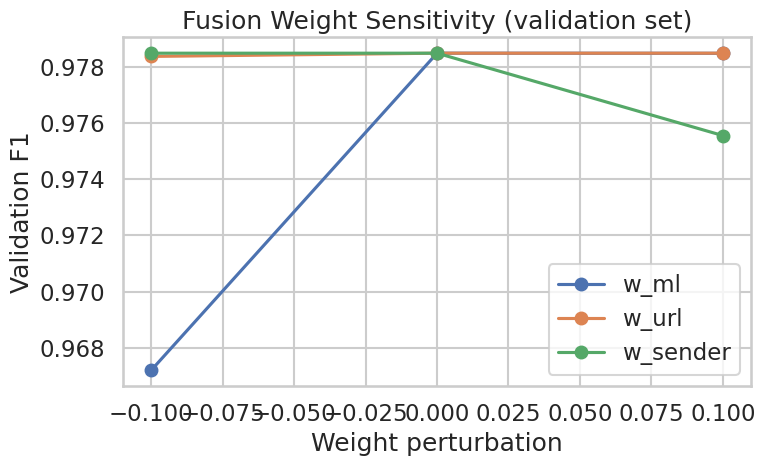

Sensitivity analysis saved: figures/fusion_weight_sensitivity.png


In [26]:
# ── Sensitivity analysis (+-0.10 per weight, selected configuration) ─────
sensitivity_rows = []
for key in ["ml", "url", "sender"]:
    for delta in [-0.10, 0.0, 0.10]:
        w = dict(SELECTED_WEIGHTS)
        w[key] = round(w[key] + delta, 2)
        remaining = [k for k in w if k != key]
        scale = (1 - w[key]) / sum(SELECTED_WEIGHTS[k] for k in remaining)
        for k in remaining:
            w[k] = round(SELECTED_WEIGHTS[k] * scale, 3)
        f1 = evaluate_weights(val_df, w, y_val)
        sensitivity_rows.append({"perturbed_weight": key, "delta": delta, "val_f1": f1})

sensitivity_df = pd.DataFrame(sensitivity_rows)
fig, ax = plt.subplots(figsize=(8, 5))
for key in ["ml", "url", "sender"]:
    sub = sensitivity_df[sensitivity_df["perturbed_weight"] == key]
    ax.plot(sub["delta"], sub["val_f1"], marker="o", label=f"w_{key}")
ax.set_xlabel("Weight perturbation"); ax.set_ylabel("Validation F1")
ax.set_title("Fusion Weight Sensitivity (validation set)")
ax.legend()
fig.tight_layout()
fig.savefig(DIRS["figures"] / "fusion_weight_sensitivity.png", dpi=300)
plt.show()
print("Sensitivity analysis saved: figures/fusion_weight_sensitivity.png")


In [27]:
# ── Lock final configuration ──────────────────────────────────────────────
FUSION_CONFIG_LOCKED = {
    "weights": SELECTED_WEIGHTS,
    "confidence_gate_threshold": CONFIDENCE_GATE_THRESHOLD,
    "rule_delta_cap": RULE_DELTA_CAP,
    "operating_threshold_ml_engine": OPERATING_THRESHOLD,
    "validated_on": "validation split only",
    "validation_f1_at_selected_config": float(best_row["val_f1"]),
}
print("Configuration LOCKED for Section 6 (test evaluation):")
print(json.dumps(FUSION_CONFIG_LOCKED, indent=2))


Configuration LOCKED for Section 6 (test evaluation):
{
  "weights": {
    "ml": 0.3,
    "url": 0.3,
    "sender": 0.4
  },
  "confidence_gate_threshold": 0.5,
  "rule_delta_cap": 0.15,
  "operating_threshold_ml_engine": 0.25,
  "validated_on": "validation split only",
  "validation_f1_at_selected_config": 0.9781580725061922
}


## 6. Full Hybrid System Test Evaluation

**This is the only section that accesses `test_df_HOLDOUT` for the hybrid
system.** The locked configuration from Section 5 is applied once. All five
metrics are computed with bootstrap 95% CIs, the result is appended to
`baseline_results.csv` (idempotently, matching the guard already frozen in
Notebook 03), and the four-way comparison table is printed.


In [28]:
# ── Bootstrap CI helper (identical procedure to Notebook 03) ─────────────
def bootstrap_ci(y_true, y_pred, y_proba, metric_fn, n_bootstrap=1000, ci=0.95):
    rng = np.random.RandomState(SEED)
    n = len(y_true)
    scores = [metric_fn(y_true[idx], y_pred[idx], y_proba[idx])
              for idx in (rng.randint(0, n, n) for _ in range(n_bootstrap))]
    alpha = (1 - ci) / 2
    return np.percentile(scores, [alpha * 100, (1 - alpha) * 100])

def _f1_fn(yt, yp, _):  return f1_score(yt, yp, pos_label=1, zero_division=0)
def _auc_fn(yt, _, ypr): return roc_auc_score(yt, ypr) if len(np.unique(yt)) > 1 else float("nan")
print("Bootstrap CI helper ready.")


Bootstrap CI helper ready.


In [29]:
# ── TEST SET INFERENCE (first and only access to test_df_HOLDOUT) ───────
print("Running the full hybrid pipeline on the test set "
      "(first and only access to test_df_HOLDOUT)...")
test_df_HOLDOUT = test_df_HOLDOUT.merge(
    distilbert_test_predictions[["row_id"]], on="row_id", how="inner")
test_df_HOLDOUT["_split"] = "test"

hybrid_results = test_df_HOLDOUT.apply(
    lambda r: run_hybrid_pipeline(r, weights=SELECTED_WEIGHTS), axis=1, result_type="expand")

y_test = (test_df_HOLDOUT["label"] == FRAUD_LABEL).astype(int).values
y_test_pred = hybrid_results["y_pred"].values
test_proba_hybrid = hybrid_results["risk_final"].values

test_acc  = accuracy_score(y_test, y_test_pred)
test_prec = precision_score(y_test, y_test_pred, pos_label=1, zero_division=0)
test_rec  = recall_score(y_test, y_test_pred, pos_label=1, zero_division=0)
test_f1   = f1_score(y_test, y_test_pred, pos_label=1, zero_division=0)
test_auc  = roc_auc_score(y_test, test_proba_hybrid)

f1_lo, f1_hi   = bootstrap_ci(y_test, y_test_pred, test_proba_hybrid, _f1_fn)
auc_lo, auc_hi = bootstrap_ci(y_test, y_test_pred, test_proba_hybrid, _auc_fn)

print(f"\nHybrid System — Test Set Results")
print(f"  Accuracy  : {test_acc:.4f}")
print(f"  Precision : {test_prec:.4f}")
print(f"  Recall    : {test_rec:.4f}")
print(f"  F1        : {test_f1:.4f}  [95% CI: {f1_lo:.4f} - {f1_hi:.4f}]")
print(f"  ROC-AUC   : {test_auc:.4f}  [95% CI: {auc_lo:.4f} - {auc_hi:.4f}]")


Running the full hybrid pipeline on the test set (first and only access to test_df_HOLDOUT)...

Hybrid System — Test Set Results
  Accuracy  : 0.9815
  Precision : 0.9799
  Recall    : 0.9735
  F1        : 0.9767  [95% CI: 0.9734 - 0.9798]
  ROC-AUC   : 0.9969  [95% CI: 0.9960 - 0.9977]


In [30]:
hybrid_test_predictions = hybrid_results.reset_index(drop=True)
hybrid_test_predictions.to_csv(DIRS["reports"] / "hybrid_test_predictions.csv", index=False)
print(f"hybrid_test_predictions.csv saved ({len(hybrid_test_predictions):,} rows).")

hybrid_test_predictions.csv saved (11,165 rows).


In [31]:
# ── Append to baseline_results.csv — idempotent, matching NB03's guard ───
new_row = pd.DataFrame([{
    "model": "hybrid_neuro_symbolic", "split": "test",
    "accuracy": test_acc, "precision": test_prec, "recall": test_rec,
    "f1": test_f1, "roc_auc": test_auc, "f1_at_threshold": test_f1,
    "f1_ci_lower": f1_lo, "f1_ci_upper": f1_hi,
    "auc_ci_lower": auc_lo, "auc_ci_upper": auc_hi,
}])
assert list(new_row.columns) == EXPECTED_BASELINE_COLS, "New row column mismatch."

dup_mask = (baseline_results["model"] == "hybrid_neuro_symbolic") & (baseline_results["split"] == "test")
if dup_mask.any():
    print(f"Found {dup_mask.sum()} existing hybrid/test row(s) — replacing (idempotent).")
    baseline_results = baseline_results[~dup_mask].reset_index(drop=True)

baseline_results = pd.concat([baseline_results, new_row], ignore_index=True)
baseline_results.to_csv(baseline_results_path, index=False)
print(f"baseline_results.csv updated ({len(baseline_results)} rows).")


Found 1 existing hybrid/test row(s) — replacing (idempotent).
baseline_results.csv updated (8 rows).


In [32]:
# ── Four-way comparison table ─────────────────────────────────────────────
print("=" * 80)
print("FOUR-MODEL COMPARISON TABLE (test set)")
print("=" * 80)
test_rows = baseline_results[baseline_results["split"] == "test"]
print(test_rows[["model", "accuracy", "precision", "recall", "f1", "roc_auc",
                  "f1_ci_lower", "f1_ci_upper"]].to_string(index=False))

hybrid_f1 = test_rows.loc[test_rows["model"] == "hybrid_neuro_symbolic", "f1"].values[0]
dbert_f1  = test_rows.loc[test_rows["model"] == "distilbert_fp32", "f1"].values[0]
svm_f1    = test_rows.loc[test_rows["model"] == "linear_svm", "f1"].values[0]
print(f"\nHybrid vs. DistilBERT standalone : {hybrid_f1 - dbert_f1:+.4f} F1")
print(f"Hybrid vs. best classical baseline (SVM) : {hybrid_f1 - svm_f1:+.4f} F1")


FOUR-MODEL COMPARISON TABLE (test set)
                model  accuracy  precision   recall       f1  roc_auc  f1_ci_lower  f1_ci_upper
  logistic_regression  0.978325   0.971109 0.974601 0.972852 0.996233     0.969344     0.976145
           linear_svm  0.978773   0.972409 0.974376 0.973392 0.996143     0.969903     0.976740
      distilbert_fp32  0.987013   0.982295 0.985165 0.983728 0.998682     0.981245     0.986259
hybrid_neuro_symbolic  0.981460   0.979864 0.973477 0.976660 0.996934     0.973442     0.979821

Hybrid vs. DistilBERT standalone : -0.0071 F1
Hybrid vs. best classical baseline (SVM) : +0.0033 F1


## 7. Ablation Study

The central experimental section. Every condition is evaluated on the same
test set, with the same preprocessing, threshold, and Decision Controller
logic — the only variable is which engines contribute to fusion. Per the
frozen blueprint's Revision 3, fusion weights of the remaining active engines
are **renormalized to sum to 1.0** for each condition, so that a reduced
condition's `risk_final` can in principle reach every decision state; without
this, a partial condition would be structurally capped below the BLOCK
threshold regardless of signal quality. Per Revision 4, the "ML only" row is
re-run through this same Decision Controller pipeline rather than citing
Notebook 03's differently-evaluated standalone figure.


In [33]:
# ── Ablation condition definitions and weight renormalization ────────────
ABLATION_CONDITIONS = {
    "full_hybrid":          ("rule", "ml", "url", "sender"),
    "minus_rule_engine":    ("ml", "url", "sender"),
    "minus_url_engine":     ("rule", "ml", "sender"),
    "minus_sender_context": ("rule", "ml", "url"),
    "minus_ml_use_svm":     ("rule", "ml", "url", "sender"),   # SVM substituted for DistilBERT
    "ml_only":              ("ml",),
    "rule_only":            ("rule",),
    "url_only":             ("url",),
    "sender_only":          ("sender",),
    "rule_plus_ml":         ("rule", "ml"),
    "rule_plus_ml_plus_url":("rule", "ml", "url"),
}
BASE_W = {"ml": SELECTED_WEIGHTS["ml"], "url": SELECTED_WEIGHTS["url"], "sender": SELECTED_WEIGHTS["sender"]}

def renormalized_weights(active_engines):
    '''Renormalize the weights of engines present in active_engines (among
    ml/url/sender) to sum to 1.0, preserving relative proportions. rule_delta
    is untouched — it is a bounded adjustment, not part of the weighted sum.'''
    active_weighted = [e for e in ("ml", "url", "sender") if e in active_engines]
    if not active_weighted:
        return {"ml": 0.0, "url": 0.0, "sender": 0.0}
    total = sum(BASE_W[e] for e in active_weighted)
    return {e: (BASE_W[e] / total if e in active_weighted else 0.0) for e in ("ml", "url", "sender")}

for name, engines in ABLATION_CONDITIONS.items():
    print(f"  {name:<24} engines={engines}  renorm_weights={renormalized_weights(engines)}")


  full_hybrid              engines=('rule', 'ml', 'url', 'sender')  renorm_weights={'ml': np.float64(0.3), 'url': np.float64(0.3), 'sender': np.float64(0.4)}
  minus_rule_engine        engines=('ml', 'url', 'sender')  renorm_weights={'ml': np.float64(0.3), 'url': np.float64(0.3), 'sender': np.float64(0.4)}
  minus_url_engine         engines=('rule', 'ml', 'sender')  renorm_weights={'ml': np.float64(0.4285714285714286), 'url': 0.0, 'sender': np.float64(0.5714285714285715)}
  minus_sender_context     engines=('rule', 'ml', 'url')  renorm_weights={'ml': np.float64(0.5), 'url': np.float64(0.5), 'sender': 0.0}
  minus_ml_use_svm         engines=('rule', 'ml', 'url', 'sender')  renorm_weights={'ml': np.float64(0.3), 'url': np.float64(0.3), 'sender': np.float64(0.4)}
  ml_only                  engines=('ml',)  renorm_weights={'ml': np.float64(1.0), 'url': 0.0, 'sender': 0.0}
  rule_only                engines=('rule',)  renorm_weights={'ml': 0.0, 'url': 0.0, 'sender': 0.0}
  url_only         

In [34]:
# ── Run every ablation condition on the (already-quarantined) test set ────
ablation_rows = []
for condition, engines in ABLATION_CONDITIONS.items():
    w = renormalized_weights(engines)

    if condition == "minus_ml_use_svm":
        # SVM substituted for DistilBERT: transform test messages with NB02's
        # frozen vectoriser and use SVM's probability as the ml_score slot.
        clean_msgs = test_df_HOLDOUT["message"].apply(lambda m: preprocess_message(m)[0])
        svm_proba = svm_model.predict_proba(tfidf_vectorizer.transform(clean_msgs))[:, 1]
        preds = test_df_HOLDOUT.assign(_svm_proba=svm_proba).apply(
            lambda r: run_hybrid_pipeline(r, weights=w, active_engines=engines,
                                           ml_score_override=r["_svm_proba"])["y_pred"], axis=1)
        proba_for_auc = svm_proba
    else:
        results = test_df_HOLDOUT.apply(
            lambda r: run_hybrid_pipeline(r, weights=w, active_engines=engines),
            axis=1, result_type="expand")
        preds = results["y_pred"].values
        proba_for_auc = results["risk_final"].values

    f1  = f1_score(y_test, preds, pos_label=1, zero_division=0)
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, pos_label=1, zero_division=0)
    rec  = recall_score(y_test, preds, pos_label=1, zero_division=0)
    auc  = roc_auc_score(y_test, proba_for_auc)
    f1lo, f1hi = bootstrap_ci(y_test, preds, proba_for_auc, _f1_fn)

    ablation_rows.append({
        "condition": condition, "engines": "+".join(engines),
        "accuracy": acc, "precision": prec, "recall": rec, "f1": f1,
        "roc_auc": auc, "f1_ci_lower": f1lo, "f1_ci_upper": f1hi,
        "delta_vs_distilbert_standalone": f1 - dbert_f1,
    })
    print(f"  {condition:<24} F1={f1:.4f}")

ablation_results = pd.DataFrame(ablation_rows).sort_values("f1", ascending=False).reset_index(drop=True)
ablation_results.to_csv(DIRS["reports"] / "ablation_results.csv", index=False)
print(f"\nablation_results.csv saved ({len(ablation_results)} conditions).")


  full_hybrid              F1=0.9767
  minus_rule_engine        F1=0.9830
  minus_url_engine         F1=0.9753
  minus_sender_context     F1=0.9767
  minus_ml_use_svm         F1=0.9633
  ml_only                  F1=0.9834
  rule_only                F1=0.0844
  url_only                 F1=0.0982
  sender_only              F1=0.5533
  rule_plus_ml             F1=0.9771
  rule_plus_ml_plus_url    F1=0.9767

ablation_results.csv saved (11 conditions).


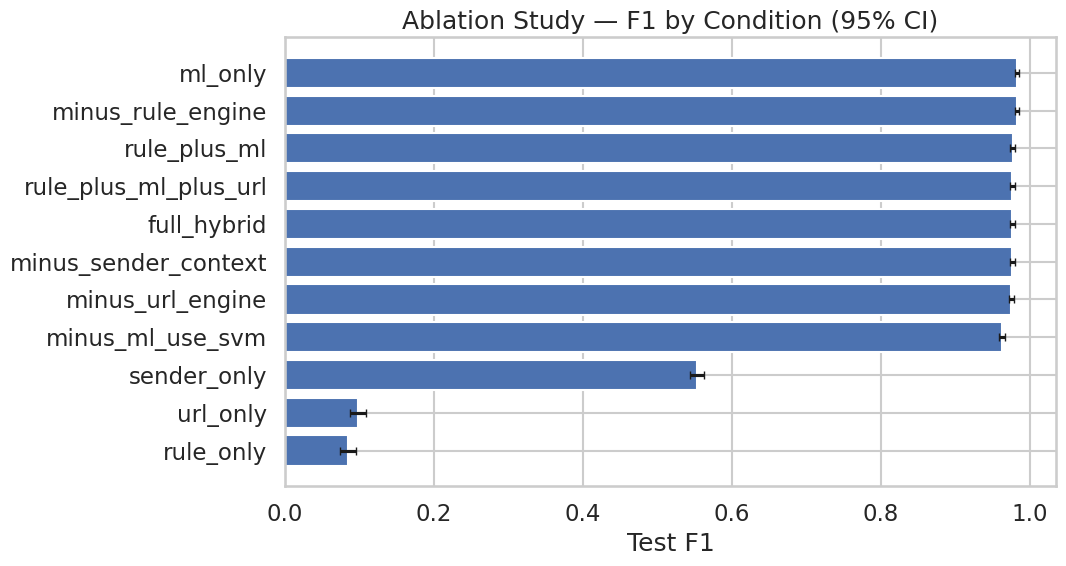

            condition       f1  delta_vs_distilbert_standalone
              ml_only 0.983412                       -0.000316
    minus_rule_engine 0.982975                       -0.000753
         rule_plus_ml 0.977096                       -0.006632
rule_plus_ml_plus_url 0.976660                       -0.007068
          full_hybrid 0.976660                       -0.007068
 minus_sender_context 0.976660                       -0.007068
     minus_url_engine 0.975264                       -0.008464
     minus_ml_use_svm 0.963269                       -0.020459
          sender_only 0.553277                       -0.430451
             url_only 0.098186                       -0.885542
            rule_only 0.084392                       -0.899336


In [35]:
# ── Ablation bar chart (F1 by condition, with CI error bars) ─────────────
fig, ax = plt.subplots(figsize=(11, 6))
err = [ablation_results["f1"] - ablation_results["f1_ci_lower"],
       ablation_results["f1_ci_upper"] - ablation_results["f1"]]
ax.barh(ablation_results["condition"], ablation_results["f1"], xerr=err, capsize=3)
ax.invert_yaxis()
ax.set_xlabel("Test F1"); ax.set_title("Ablation Study — F1 by Condition (95% CI)")
fig.tight_layout()
fig.savefig(DIRS["figures"] / "ablation_bar_chart.png", dpi=300)
plt.show()
print(ablation_results[["condition", "f1", "delta_vs_distilbert_standalone"]].to_string(index=False))


## 8. Cross-Model Error Recovery Analysis

Uses Notebook 03's `cross_model_analysis.csv` (SVM vs. DistilBERT) as the
starting point, and checks whether the hybrid system correctly classifies
each previously-`shared_error` message. This recovery rate from the hardest
error category is the primary quantitative evidence for the hybrid system's
contribution beyond either individual component.


In [36]:
# ── Three-way recovery: SVM -> DistilBERT -> Hybrid ──────────────────────
recovery_df = cross_model_analysis.merge(
    hybrid_test_predictions[["row_id", "y_pred"]].rename(columns={"y_pred": "hybrid_pred"}),
    on="row_id", how="inner")
recovery_df["hybrid_ok"] = recovery_df["hybrid_pred"] == recovery_df["y_true"]

shared_error_mask = recovery_df["cross_model_category"] == "shared_error"
n_shared_errors = shared_error_mask.sum()
n_recovered_by_hybrid = (shared_error_mask & recovery_df["hybrid_ok"]).sum()
recovery_rate = n_recovered_by_hybrid / n_shared_errors if n_shared_errors else float("nan")

print(f"SVM+DistilBERT shared errors : {n_shared_errors:,}")
print(f"  Recovered by hybrid system  : {n_recovered_by_hybrid:,} ({recovery_rate:.1%})")
print(f"  Still unresolved            : {n_shared_errors - n_recovered_by_hybrid:,}")

recovery_df.to_csv(DIRS["error"] / "three_way_error_recovery.csv", index=False)
print("three_way_error_recovery.csv saved.")


SVM+DistilBERT shared errors : 81
  Recovered by hybrid system  : 2 (2.5%)
  Still unresolved            : 79
three_way_error_recovery.csv saved.


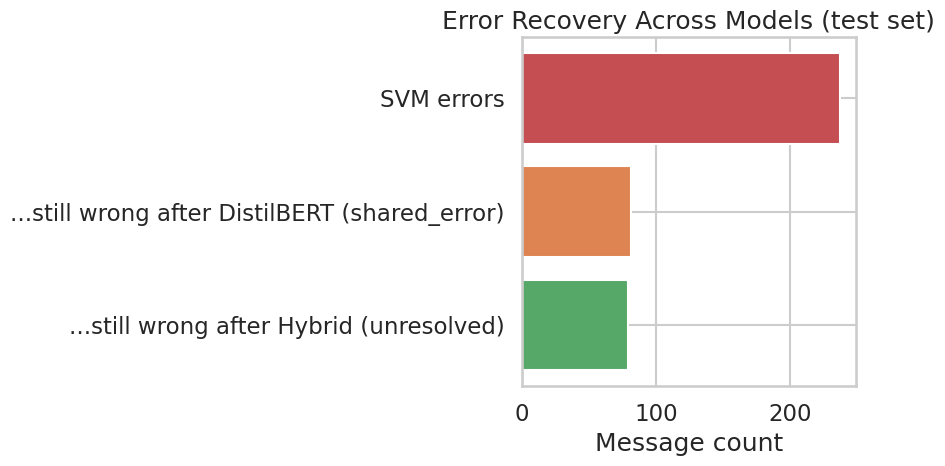

In [37]:
# ── Error-flow figure (SVM -> DistilBERT -> Hybrid) ──────────────────────
# Alluvial/Sankey-style flow rendered with a simple stage bar chart
# (avoids adding a new plotting dependency beyond matplotlib/seaborn).
stage_counts = pd.DataFrame({
    "stage": ["SVM errors", "...still wrong after DistilBERT (shared_error)",
              "...still wrong after Hybrid (unresolved)"],
    "count": [
        (cross_model_analysis["cross_model_category"].isin(["shared_error", "resolved_error"])).sum(),
        n_shared_errors,
        n_shared_errors - n_recovered_by_hybrid,
    ],
})
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(stage_counts["stage"], stage_counts["count"], color=["#c44e52", "#dd8452", "#55a868"])
ax.invert_yaxis()
ax.set_xlabel("Message count"); ax.set_title("Error Recovery Across Models (test set)")
fig.tight_layout()
fig.savefig(DIRS["figures"] / "error_recovery_sankey.png", dpi=300)
plt.show()


## 9. Explainability

Decision traces, rule-firing evidence, attention highlights, and LIME on a
curated sample of 20 test-set decisions (10 BLOCK, 10 ESCALATE, stratified by
`rule_category`). This is a system-level explanation (how a *decision* was
reached) and is complementary to, not redundant with, Notebook 03's
model-level attention diagnostics. Attention and LIME here explain the ML
engine's contribution to the fused decision specifically, not the fused
decision as a whole.


In [38]:
# ── Decision traces for every BLOCK / ESCALATE test decision ─────────────
block_escalate = hybrid_test_predictions[
    hybrid_test_predictions["decision"].isin(["BLOCK", "ESCALATE"])
].copy()

def primary_contributor(row):
    contributions = {
        "ml": SELECTED_WEIGHTS["ml"] * row["ml_score"],
        "url": SELECTED_WEIGHTS["url"] * row["url_risk"],
        "sender": SELECTED_WEIGHTS["sender"] * row["sender_risk"],
        "rule": abs(compute_rule_delta(0.80)) if row["rule_label"] not in ("normal", "n/a") else 0.0,
    }
    return max(contributions, key=contributions.get)

block_escalate["primary_contributor"] = block_escalate.apply(primary_contributor, axis=1)
block_escalate.to_csv(DIRS["reports"] / "decision_traces.csv", index=False)
print(f"decision_traces.csv saved ({len(block_escalate):,} BLOCK/ESCALATE decisions).")


decision_traces.csv saved (4,420 BLOCK/ESCALATE decisions).


In [39]:
# ── Curate 20 decisions (10 BLOCK, 10 ESCALATE, stratified by rule_category) ─
def curate(df, decision_label, n):
    subset = df[df["decision"] == decision_label]
    cats = subset["rule_label"].unique().tolist()
    picked, used = [], set()
    for cat in cats:
        pool = subset[(subset["rule_label"] == cat) & (~subset.index.isin(used))]
        if len(pool):
            row = pool.sample(1, random_state=SEED)
            picked.append(row); used.update(row.index)
        if len(picked) >= n:
            break
    remaining = n - len(picked)
    if remaining > 0:
        pool = subset[~subset.index.isin(used)]
        picked.append(pool.sample(min(remaining, len(pool)), random_state=SEED))
    return pd.concat(picked).head(n)

curated = pd.concat([
    curate(block_escalate, "BLOCK", 10),
    curate(block_escalate, "ESCALATE", 10),
]).reset_index(drop=True)
assert curated["row_id"].duplicated().sum() == 0
print(f"Curated {len(curated)} decisions for explainability (deterministic, seed={SEED}).")


Curated 20 decisions for explainability (deterministic, seed=42).


In [40]:
# ── Attention highlights (live inference on the curated 20 only) ────────
curated_messages = test_df_HOLDOUT.set_index("row_id").loc[curated["row_id"], "message"].values

@torch.no_grad()
def top_attention_tokens(message_clean: str, top_k=5):
    inputs = distilbert_tokenizer(message_clean, truncation=True, padding="max_length",
                                   max_length=nb03_training_args["max_length"],
                                   return_tensors="pt").to(device)
    out = distilbert_model(**inputs, output_attentions=True)
    last_layer_attn = out.attentions[-1].mean(dim=1)[0]        # avg over heads
    token_scores = last_layer_attn.mean(dim=0)                 # avg over query positions
    tokens = distilbert_tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    ranked = sorted(zip(tokens, token_scores.tolist()), key=lambda x: -x[1])
    return [t for t, _ in ranked if t not in ("[PAD]", "[CLS]", "[SEP]")][:top_k]

curated = curated.copy()
curated["top_attention_tokens"] = [
    top_attention_tokens(preprocess_message(m)[0]) for m in curated_messages
]
print("Attention highlights computed for the curated sample (memory-guarded: 20 calls only).")


DistilBertSdpaAttention is used but `torch.nn.functional.scaled_dot_product_attention` does not support `output_attentions=True` or `head_mask`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


Attention highlights computed for the curated sample (memory-guarded: 20 calls only).


In [41]:
# ── LIME explanations (curated 20 only — ~500-1000 perturbations each) ───
from lime.lime_text import LimeTextExplainer

lime_explainer = LimeTextExplainer(class_names=["ham", "fraud"])

def ml_predict_proba(texts):
    clean = [preprocess_message(t)[0] for t in texts]
    scores = [ml_engine.score_live(c)["ml_score"] for c in clean]
    return np.array([[1 - s, s] for s in scores])

lime_top_tokens = []
for i, (row_id, msg) in enumerate(zip(curated["row_id"], curated_messages)):
    exp = lime_explainer.explain_instance(msg, ml_predict_proba, num_features=5, num_samples=500)
    top = [tok for tok, _ in exp.as_list()]
    lime_top_tokens.append(top)
    # Save each result immediately (blueprint Risk 4 mitigation: a session
    # drop during message 17 must not lose messages 1-16).
    with open(DIRS["figures"] / "lime_attention_comparison" / f"lime_{row_id}.json", "w") as f:
        json.dump({"row_id": str(row_id), "lime_top_tokens": top}, f)
    print(f"  [{i+1}/20] LIME done for row_id={row_id}")

curated["lime_top_tokens"] = lime_top_tokens
curated["attention_lime_agreement"] = curated.apply(
    lambda r: len(set(r["top_attention_tokens"]) & set(r["lime_top_tokens"])) / 5, axis=1)
print("\nLIME explanations complete for all 20 curated decisions.")
print(f"Mean attention/LIME token agreement: {curated['attention_lime_agreement'].mean():.1%}")

  [1/20] LIME done for row_id=github_fraud_compilation_67386
  [2/20] LIME done for row_id=github_fraud_compilation_84628
  [3/20] LIME done for row_id=github_fraud_compilation_28467
  [4/20] LIME done for row_id=github_fraud_compilation_56916
  [5/20] LIME done for row_id=github_fraud_compilation_22354
  [6/20] LIME done for row_id=github_fraud_compilation_32138
  [7/20] LIME done for row_id=github_fraud_compilation_32629
  [8/20] LIME done for row_id=github_fraud_compilation_69210
  [9/20] LIME done for row_id=github_fraud_compilation_19020
  [10/20] LIME done for row_id=github_fraud_compilation_62221
  [11/20] LIME done for row_id=github_fraud_compilation_34090
  [12/20] LIME done for row_id=github_fraud_compilation_42051
  [13/20] LIME done for row_id=github_fraud_compilation_81491
  [14/20] LIME done for row_id=github_fraud_compilation_41223
  [15/20] LIME done for row_id=github_fraud_compilation_18695
  [16/20] LIME done for row_id=github_fraud_compilation_74867
  [17/20] LIME do

In [42]:
# ── Save curated human-readable traces for the dissertation appendix ────
decision_traces_curated = []
for _, r in curated.iterrows():
    decision_traces_curated.append({
        "row_id": str(r["row_id"]), "decision": r["decision"], "reason": r["reason"],
        "rule_label": r["rule_label"], "risk_final": round(float(r["risk_final"]), 4),
        "primary_contributor": r["primary_contributor"],
        "top_attention_tokens": r["top_attention_tokens"],
        "lime_top_tokens": r["lime_top_tokens"],
        "attention_lime_agreement": round(float(r["attention_lime_agreement"]), 2),
    })

with open(DIRS["reports"] / "decision_traces_curated.json", "w") as f:
    json.dump(decision_traces_curated, f, indent=2)
print(f"decision_traces_curated.json saved ({len(decision_traces_curated)} traces).")

decision_traces_curated.json saved (20 traces).


## 10. Statistical Testing and Comparison Figures

McNemar's test for hybrid vs. SVM and hybrid vs. DistilBERT (paired binary
predictions on the identical test set), plus the four-model ROC/PR figures
and the false-positive-rate secondary table.


In [43]:
# ── McNemar's test ────────────────────────────────────────────────────────
def mcnemar_test(y_true, pred_a, pred_b):
    a_correct = pred_a == y_true
    b_correct = pred_b == y_true
    table = [[np.sum(a_correct & b_correct),  np.sum(a_correct & ~b_correct)],
             [np.sum(~a_correct & b_correct), np.sum(~a_correct & ~b_correct)]]
    result = mcnemar(table, exact=False, correction=True)
    return {"statistic": float(result.statistic), "p_value": float(result.pvalue)}

clean_msgs_svm = test_df_HOLDOUT["message"].apply(lambda m: preprocess_message(m)[0])
svm_test_proba = svm_model.predict_proba(tfidf_vectorizer.transform(clean_msgs_svm))[:, 1]
svm_test_pred = (svm_test_proba >= 0.5).astype(int)
dbert_test_pred = (distilbert_test_predictions.set_index("row_id")
                    .loc[test_df_HOLDOUT["row_id"], "y_proba_fraud"].values >= OPERATING_THRESHOLD).astype(int)

mcnemar_results = {
    "hybrid_vs_svm":        mcnemar_test(y_test, y_test_pred, svm_test_pred),
    "hybrid_vs_distilbert": mcnemar_test(y_test, y_test_pred, dbert_test_pred),
}
with open(DIRS["reports"] / "mcnemar_test_results.json", "w") as f:
    json.dump(mcnemar_results, f, indent=2)
print(json.dumps(mcnemar_results, indent=2))


{
  "hybrid_vs_svm": {
    "statistic": 3.1148148148148147,
    "p_value": 0.07758329748513149
  },
  "hybrid_vs_distilbert": {
    "statistic": 48.96052631578947,
    "p_value": 2.6116588838968093e-12
  }
}


In [44]:
# ── False positive rate secondary table (four models, by FP source) ─────
def fp_rate_by_source(fp_df, total_n, model_name):
    counts = fp_df["source"].value_counts() if "source" in fp_df.columns else pd.Series(dtype=int)
    return {"model": model_name, "fp_count": len(fp_df), "fp_rate": len(fp_df) / total_n,
            **{f"fp_{src}": int(n) for src, n in counts.items()}}

hybrid_fp = hybrid_test_predictions[
    (hybrid_test_predictions["y_pred"] == 1) &
    (hybrid_test_predictions["row_id"].isin(
        test_df_HOLDOUT.loc[test_df_HOLDOUT["label"] == HAM_LABEL, "row_id"]))
]
fp_table = pd.DataFrame([
    fp_rate_by_source(nb02_fp[nb02_fp["model"] == "linear_svm"] if "model" in nb02_fp.columns else nb02_fp,
                       len(test_df_HOLDOUT), "linear_svm"),
    fp_rate_by_source(nb03_fp, len(test_df_HOLDOUT), "distilbert_fp32"),
    fp_rate_by_source(hybrid_fp.merge(test_df_HOLDOUT[["row_id", "source"]], on="row_id"),
                       len(test_df_HOLDOUT), "hybrid_neuro_symbolic"),
])
fp_table.to_csv(DIRS["error"] / "false_positive_rate_comparison.csv", index=False)
print(fp_table.to_string(index=False))


                model  fp_count  fp_rate  fp_github_fraud_compilation  fp_uci_sms_spam
           linear_svm       123 0.011017                          115              8.0
      distilbert_fp32        79 0.007076                           79              NaN
hybrid_neuro_symbolic        89 0.007971                           89              NaN


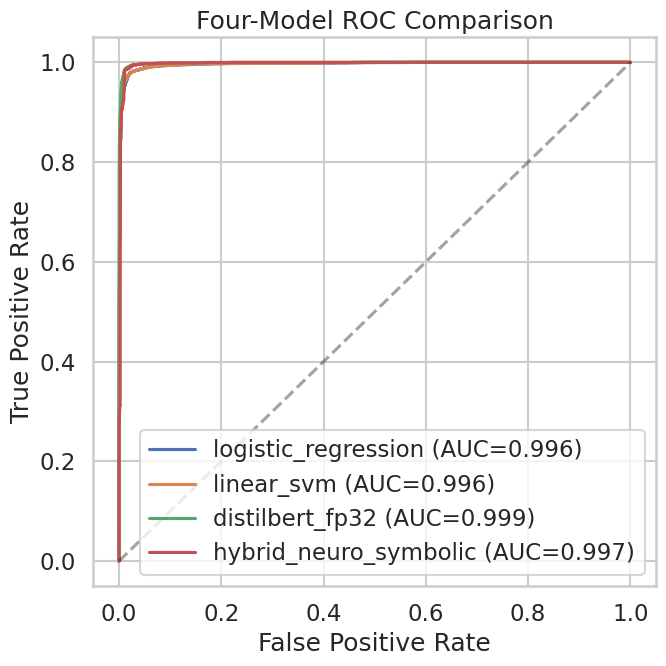

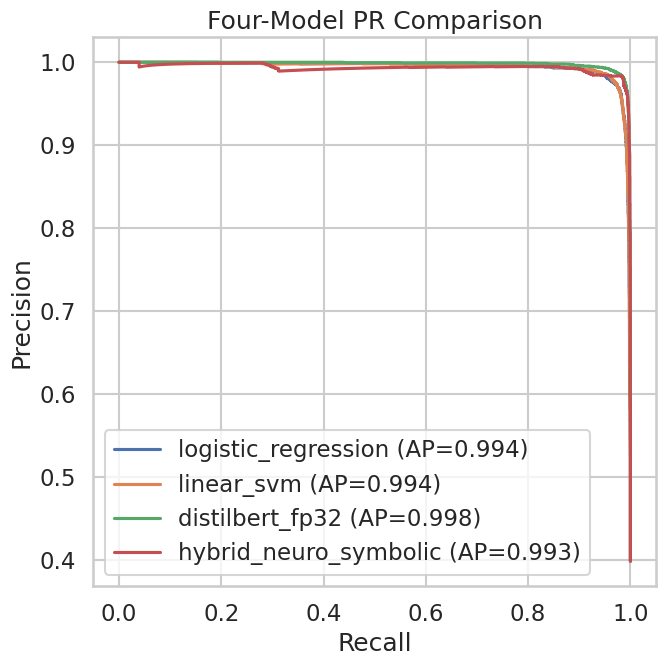

In [45]:
# ── Four-model ROC / PR comparison figures ───────────────────────────────
lr_test_proba = lr_model.predict_proba(tfidf_vectorizer.transform(clean_msgs_svm))[:, 1]

curves = {
    "logistic_regression": lr_test_proba,
    "linear_svm": svm_test_proba,
    "distilbert_fp32": distilbert_test_predictions.set_index("row_id").loc[test_df_HOLDOUT["row_id"], "y_proba_fraud"].values,
    "hybrid_neuro_symbolic": test_proba_hybrid,
}

fig, ax = plt.subplots(figsize=(7, 7))
for label, proba in curves.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("Four-Model ROC Comparison"); ax.legend()
fig.tight_layout(); fig.savefig(DIRS["figures"] / "roc_curves" / "four_model_comparison.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(7, 7))
for label, proba in curves.items():
    p, r, _ = precision_recall_curve(y_test, proba)
    ax.plot(r, p, label=f"{label} (AP={average_precision_score(y_test, proba):.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Four-Model PR Comparison"); ax.legend()
fig.tight_layout(); fig.savefig(DIRS["figures"] / "pr_curves" / "four_model_comparison.png", dpi=300)
plt.show()


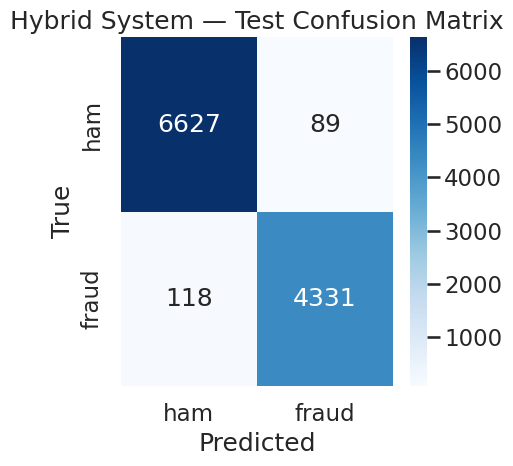

In [46]:
# ── Hybrid confusion matrix ───────────────────────────────────────────────
cm = confusion_matrix(y_test, y_test_pred)
fig, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["ham", "fraud"],
            yticklabels=["ham", "fraud"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Hybrid System — Test Confusion Matrix")
fig.tight_layout()
fig.savefig(DIRS["figures"] / "confusion_matrices" / "hybrid_test.png", dpi=300)
plt.show()


## 11. Artifact Export and Final Summary

Writes `fusion_config.json` and `04_hybrid_summary.json`, programmatically
verifies every required artifact exists, and prints the notebook's final
report in the pipeline's standard format.


In [47]:
# ── fusion_config.json (functional input to Notebook 05) ─────────────────
fusion_config = {
    "weights": SELECTED_WEIGHTS,
    "confidence_gate_threshold": CONFIDENCE_GATE_THRESHOLD,
    "rule_delta_cap": RULE_DELTA_CAP,
    "operating_threshold_ml_engine": OPERATING_THRESHOLD,
    "decision_thresholds": {"pass_max": 0.25, "escalate_max": 0.65},
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
}
with open(DIRS["reports"] / "fusion_config.json", "w") as f:
    json.dump(fusion_config, f, indent=2)
print("fusion_config.json saved.")


fusion_config.json saved.


In [48]:
# ── 04_hybrid_summary.json ────────────────────────────────────────────────
hybrid_summary = {
    "notebook": "04_Hybrid_Neuro_Symbolic_Architecture.ipynb",
    "pipeline_position": "4 of 5",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "random_seed": SEED,
    "notebook_01_checksums_verified": expected_checksums,
    "notebook_03_generated_utc": nb03_summary["generated_at_utc"],
    "fusion_config": fusion_config,
    "test_metrics": {
        "accuracy": float(test_acc), "precision": float(test_prec), "recall": float(test_rec),
        "f1": float(test_f1), "roc_auc": float(test_auc),
        "f1_ci": [float(f1_lo), float(f1_hi)], "auc_ci": [float(auc_lo), float(auc_hi)],
    },
    "comparison_vs_baselines": {
        "vs_distilbert_standalone": float(test_f1 - dbert_f1),
        "vs_best_classical_baseline": float(test_f1 - svm_f1),
    },
    "best_ablation_condition": ablation_results.iloc[0]["condition"],
    "best_ablation_f1": float(ablation_results.iloc[0]["f1"]),
    "mcnemar_test_results": mcnemar_results,
    "error_recovery": {
        "shared_errors_total": int(n_shared_errors),
        "recovered_by_hybrid": int(n_recovered_by_hybrid),
        "recovery_rate": float(recovery_rate),
    },
}
with open(DIRS["reports"] / "04_hybrid_summary.json", "w") as f:
    json.dump(hybrid_summary, f, indent=2)
print("04_hybrid_summary.json saved.")


04_hybrid_summary.json saved.


In [49]:
# ── Artifact verification ─────────────────────────────────────────────────
REQUIRED = [
    DIRS["reports"] / "hybrid_test_predictions.csv",
    DIRS["reports"] / "ablation_results.csv",
    DIRS["reports"] / "decision_traces.csv",
    DIRS["reports"] / "decision_traces_curated.json",
    DIRS["reports"] / "mcnemar_test_results.json",
    DIRS["reports"] / "fusion_config.json",
    DIRS["reports"] / "04_hybrid_summary.json",
    baseline_results_path,
    DIRS["figures"] / "ablation_bar_chart.png",
    DIRS["figures"] / "confusion_matrices" / "hybrid_test.png",
    DIRS["figures"] / "roc_curves" / "four_model_comparison.png",
    DIRS["figures"] / "pr_curves" / "four_model_comparison.png",
    DIRS["figures"] / "error_recovery_sankey.png",
    DIRS["figures"] / "fusion_weight_sensitivity.png",
    DIRS["error"] / "three_way_error_recovery.csv",
    DIRS["error"] / "false_positive_rate_comparison.csv",
]
missing = [str(p) for p in REQUIRED if not p.exists() or p.stat().st_size == 0]
assert not missing, f"Missing/empty required artifacts: {missing}"
print(f"Artifact verification PASSED: {len(REQUIRED)} required files present and non-empty.")


Artifact verification PASSED: 16 required files present and non-empty.


In [50]:
# ── Final report ──────────────────────────────────────────────────────────
print("=" * 78)
print("FINAL REPORT - 04_Hybrid_Neuro_Symbolic_Architecture.ipynb")
print("=" * 78)
print(f'''
Generated      : {hybrid_summary['generated_at_utc']}
Pipeline pos   : Notebook 4 of 5
Random seed    : {SEED}
Checksums      : VERIFIED

FUSION CONFIGURATION (validated on validation set only)
---------------------------------------------------------
  Weights                 : {SELECTED_WEIGHTS}
  Confidence gate threshold : {CONFIDENCE_GATE_THRESHOLD}
  ML engine OPERATING_THRESHOLD (standalone metric / confidence only) : {OPERATING_THRESHOLD:.2f}

TEST SET RESULTS (Hybrid System)
---------------------------------------------------------
  F1        : {test_f1:.4f}  [95% CI: {f1_lo:.4f} - {f1_hi:.4f}]
  ROC-AUC   : {test_auc:.4f}  [95% CI: {auc_lo:.4f} - {auc_hi:.4f}]
  vs. DistilBERT standalone     : {test_f1 - dbert_f1:+.4f}
  vs. best classical (SVM)      : {test_f1 - svm_f1:+.4f}

ABLATION STUDY
---------------------------------------------------------
  Best condition : {ablation_results.iloc[0]['condition']} (F1={ablation_results.iloc[0]['f1']:.4f})
  Conditions evaluated : {len(ablation_results)}

ERROR RECOVERY (SVM+DistilBERT shared errors)
---------------------------------------------------------
  Shared errors    : {n_shared_errors:,}
  Recovered by hybrid : {n_recovered_by_hybrid:,} ({recovery_rate:.1%})

STATISTICAL TESTING
---------------------------------------------------------
  Hybrid vs SVM        p={mcnemar_results['hybrid_vs_svm']['p_value']:.4g}
  Hybrid vs DistilBERT p={mcnemar_results['hybrid_vs_distilbert']['p_value']:.4g}

ARTIFACTS       : {len(REQUIRED)} verified present
LEAKAGE STATUS  : test_df_HOLDOUT accessed only in Section 6 - no leakage

NEXT STEP       : Notebook 05 - Quantization, TFLite & Android Deployment
  reads: baseline_results.csv, 04_hybrid_summary.json, fusion_config.json,
         hybrid_test_predictions.csv, ablation_results.csv
''')
print("=" * 78)
print("NOTEBOOK 04 COMPLETE - ALL ARTIFACTS VERIFIED")
print("=" * 78)


FINAL REPORT - 04_Hybrid_Neuro_Symbolic_Architecture.ipynb

Generated      : 2026-07-10T04:33:56.548869+00:00
Pipeline pos   : Notebook 4 of 5
Random seed    : 42
Checksums      : VERIFIED

FUSION CONFIGURATION (validated on validation set only)
---------------------------------------------------------
  Weights                 : {'ml': np.float64(0.3), 'url': np.float64(0.3), 'sender': np.float64(0.4)}
  Confidence gate threshold : 0.5
  ML engine OPERATING_THRESHOLD (standalone metric / confidence only) : 0.25

TEST SET RESULTS (Hybrid System)
---------------------------------------------------------
  F1        : 0.9767  [95% CI: 0.9734 - 0.9798]
  ROC-AUC   : 0.9969  [95% CI: 0.9960 - 0.9977]
  vs. DistilBERT standalone     : -0.0071
  vs. best classical (SVM)      : +0.0033

ABLATION STUDY
---------------------------------------------------------
  Best condition : ml_only (F1=0.9834)
  Conditions evaluated : 11

ERROR RECOVERY (SVM+DistilBERT shared errors)
----------------------